[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/grabuffo/brain-modeling-course/blob/main/notebooks/D2_C4_NB08_bifurcations.ipynb)

# Day 2 · Chapter 4 · Notebook 08 — Bifurcations inside the models

In the slides we saw bifurcations in wings, bridges, metronomes and taps. Here we look at the same bifurcations
**inside the models of the course**, and ask two simple questions each time a rhythm (or firing) appears:

* **how big** is it when it starts?
* **how fast** is it when it starts?

| bifurcation | size at onset | speed at onset | memory | our model |
|---|---|---|---|---|
| supercritical Hopf | zero, grows gently | already fast | no | Stuart–Landau (one brain region in NB10) |
| subcritical Hopf | large, at once | already fast | yes | Hodgkin–Huxley neuron |
| saddle-node | a state disappears | – | – | the landscape of a neuron |
| SNIC (saddle-node on a cycle) | full size | starts from zero | no | active rotator, QIF / θ neuron |

The code is hidden: run each cell, and open it if you are curious.

In [1]:
# @title Setup (run once)
# On Google Colab this downloads the course code; on your laptop it does nothing.
import sys, os
if "google.colab" in sys.modules:
    if not os.path.exists("/content/brain-modeling-course"):          # first run: download the course code
        !git clone -q https://github.com/grabuffo/brain-modeling-course.git /content/brain-modeling-course
        !pip -q install numba ipywidgets
    %cd /content/brain-modeling-course/notebooks
sys.path.insert(0, os.path.abspath(".."))   # so that `import src` works

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
from src import plotting
from src.plotting import slider
plotting.setup()
from src import normal_forms as nf, neurons

## 1. Supercritical Hopf: a rhythm born small

The simplest equation with a Hopf bifurcation is the **Stuart–Landau oscillator**. It has one knob, $a$, the
**distance to the bifurcation**. In NB10 every brain region will be one of these.

* $a<0$: any push spirals back to rest;
* $a>0$: the system settles on a circle, a rhythm whose size grows like $\sqrt{a}$, while its speed (frequency) stays
  the same.

<details><summary>Equation (for the curious)</summary>

$\dot z = (a + i\omega)\,z - |z|^2 z$, with $z = x + iy$. The rhythm has radius $\sqrt a$ and frequency $\omega$.
</details>

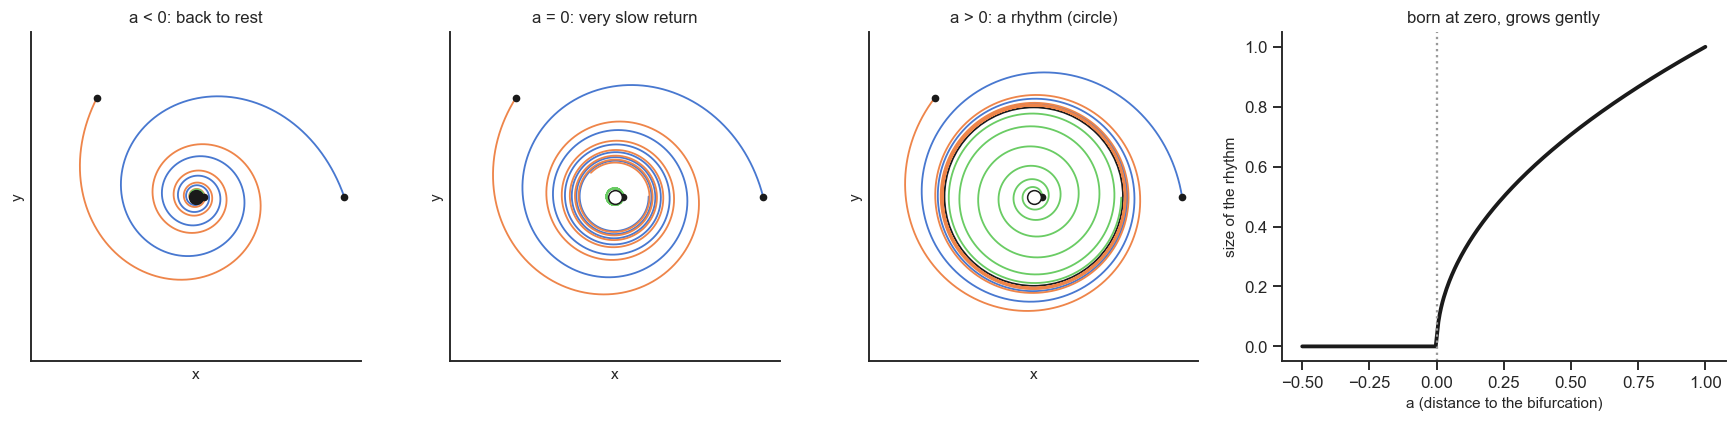

In [2]:
# @title Stuart-Landau: trajectories in the (x, y) plane below, at and above the bifurcation; size of the rhythm vs a
fig, ax = plt.subplots(1, 4, figsize=(16, 4), gridspec_kw=dict(width_ratios=[1, 1, 1, 1.3]))
starts = [0.9 + 0j, -0.6 + 0.6j, 0.05 + 0j]
for a_, a in zip(ax[:3], [-0.3, 0.0, 0.3]):
    for z0 in starts:
        t, z = nf.hopf(a, omega=2 * np.pi * 0.5, T=12, dt=1e-3, z0=z0)
        a_.plot(z.real, z.imag, lw=1.2); a_.plot(z0.real, z0.imag, "ko", ms=4)
    if a > 0: a_.add_patch(plt.Circle((0, 0), np.sqrt(a), fill=False, ec="k", lw=2.5))
    a_.plot(0, 0, "o", ms=9, mfc="k" if a < 0 else "w", mec="k")
    a_.set(xlim=(-1, 1), ylim=(-1, 1), aspect="equal", xticks=[], yticks=[], xlabel="x", ylabel="y",
           title={-0.3: "a < 0: back to rest", 0.0: "a = 0: very slow return", 0.3: "a > 0: a rhythm (circle)"}[a])
aa = np.linspace(-0.5, 1, 300)
ax[3].plot(aa, np.sqrt(np.clip(aa, 0, None)), "k", lw=2.5)
ax[3].axvline(0, c="0.6", ls=":")
ax[3].set(xlabel="a (distance to the bifurcation)", ylabel="size of the rhythm", title="born at zero, grows gently")
plt.tight_layout(); plt.show()

Each coloured line is one trajectory, from its black start dot; the central dot is rest (filled: stable, open:
unstable), the thick black circle is the rhythm. Turning $a$ back down, the rhythm shrinks along the same curve:
**no jump, no memory**.

**Close to the bifurcation, noise matters.** Just below it ($a$ slightly negative), the pull back to rest is weak:
random kicks pile up into large, slow, rhythmic waves (the *critical slowing down* of the slides). This is why
whole-brain models put their regions **near** $a=0$.

### Explore
* Move $a$ from −1 towards 0: how do the waves and the spectrum change?
* Cross to $a>0$: what is different?

In [3]:
# @title Explore: noise near a supercritical Hopf bifurcation
@interact(a=slider(-0.2, -1.0, 0.3, 0.01, "a (distance to the bifurcation)"), sigma=slider(0.02, 0.0, 0.1, 0.005, "noise"))
def explore_noisy_hopf(a, sigma):
    t, z = nf.hopf(a, np.pi, sigma=sigma, T=400, dt=1e-3, z0=0j, seed=3)
    x = z.real[t > 20][::20]
    f = np.fft.rfftfreq(x.size, 0.02); P = np.abs(np.fft.rfft(x))**2 * 0.02 / x.size
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.5), gridspec_kw=dict(width_ratios=[1.7, 1]))
    ax[0].plot(t[t > 300], z.real[t > 300], "k", lw=0.7)
    ax[0].set(xlabel="time", ylabel="x", title="a rhythm" if a > 0 else f"noise-driven waves (variance {x.var():.4f})")
    ax[1].semilogy(f, np.convolve(P, np.ones(20) / 20, "same"), "k")
    ax[1].set(xlim=(0, 1.5), xlabel="frequency", ylabel="power", title="spectrum")
    plt.tight_layout(); plt.show()

## 2. Subcritical Hopf: a large rhythm, at once, with memory

The **Hodgkin–Huxley neuron** (NB01). We raise the injected current in small steps, hold each for 0.4 s and count
the spikes; then we go back down, without ever resetting the neuron.

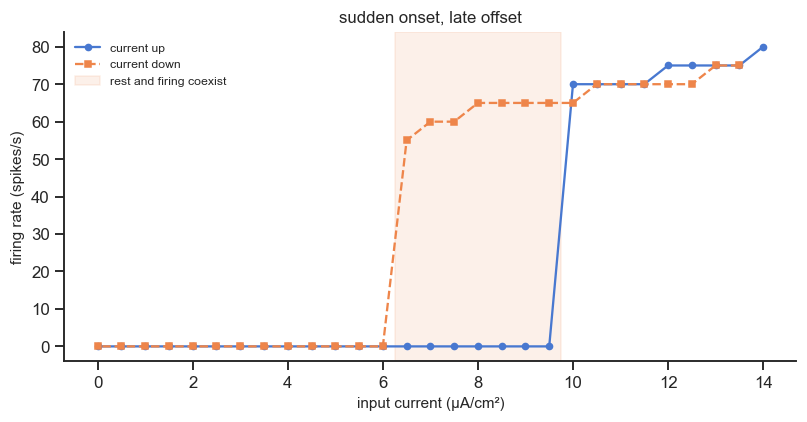

In [4]:
# @title Hodgkin-Huxley: firing rate while the current goes slowly up, then down (~2 s to run)
dt, hold = 0.01, 400.0                                          # ms
steps = np.r_[np.arange(0, 14.01, 0.5), np.arange(13.5, -0.01, -0.5)]
V, *_ = neurons.hodgkin_huxley(np.repeat(steps, int(hold / dt)), dt)
st = neurons.spike_times(V, dt)
rate = np.array([((st > k * hold + 200) & (st < (k + 1) * hold)).sum() * 1000 / 200 for k in range(len(steps))])
n_up = len(np.arange(0, 14.01, 0.5))
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(steps[:n_up], rate[:n_up], "o-", c="C0", ms=4, label="current up")
ax.plot(steps[n_up:], rate[n_up:], "s--", c="C1", ms=4, label="current down")
ax.axvspan(6.25, 9.75, color="C1", alpha=0.12, label="rest and firing coexist")
ax.set(xlabel="input current (µA/cm²)", ylabel="firing rate (spikes/s)", title="sudden onset, late offset")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

* Going up, the neuron starts firing **at once, at ~70 spikes/s**: large and already fast.
* Going down, it keeps firing well below that current.
* In between, rest and firing **coexist**: one brief pulse can switch firing on, another, well timed, switches it off.

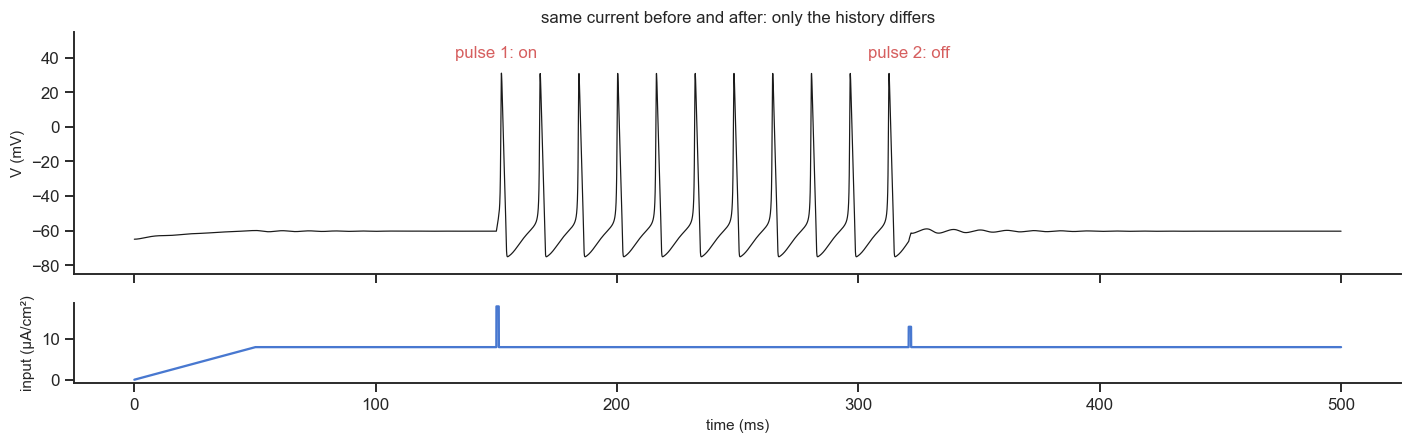

In [5]:
# @title Hodgkin-Huxley at a constant current inside the shaded range: one pulse ON, one pulse OFF
T = 500.0; t = np.arange(int(T / dt)) * dt
I = 8.0 * np.clip(t / 50, 0, 1)                                  # current raised gently to 8
I[int(150 / dt):int(151 / dt)] += 10.0                           # pulse 1 (1 ms): ON
V, *_ = neurons.hodgkin_huxley(I, dt); st = neurons.spike_times(V, dt)
t_off = st[st > 300][0] + 8.4                                    # pulse 2 (1 ms), 8.4 ms after a spike: OFF
I[int(t_off / dt):int((t_off + 1) / dt)] += 5.0
V, *_ = neurons.hodgkin_huxley(I, dt)
fig, ax = plt.subplots(2, 1, figsize=(13, 4.2), sharex=True, gridspec_kw=dict(height_ratios=[3, 1]))
ax[0].plot(t, V, "k", lw=0.8); ax[0].set(ylabel="V (mV)", ylim=(-85, 55), title="same current before and after: only the history differs")
ax[1].plot(t, I, "C0"); ax[1].set(xlabel="time (ms)", ylabel="input (µA/cm²)")
for tp, lab in [(150, "pulse 1: on"), (t_off, "pulse 2: off")]: ax[0].annotate(lab, xy=(tp, 40), ha="center", color="C3", fontsize=11)
plt.tight_layout(); plt.show()

This is the "type II" neuron: it cannot fire slowly. (Shown in the squid axon by Guttman, Lewis & Rinzel 1980.)

## 3. Saddle-node: a resting state disappears

Picture the state as a ball in a landscape. Turning the knob, a **valley** (rest) and a **hilltop** (threshold) move
towards each other, merge and **vanish**. The ball rolls away. Where it goes depends on the rest of the landscape:
to another valley (a jump to another state), or around a loop (next section).

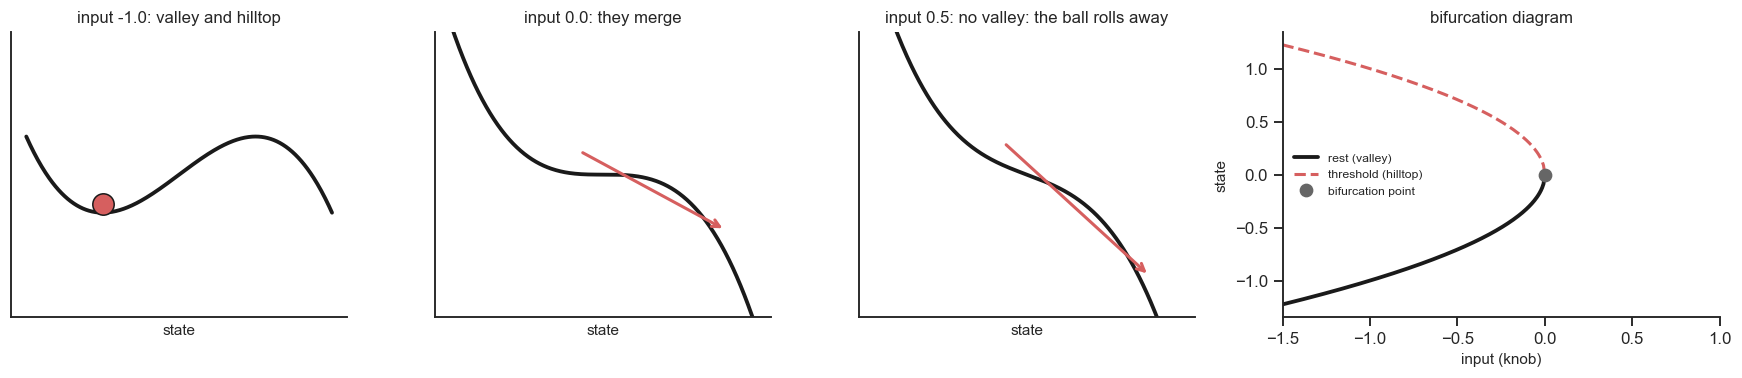

In [6]:
# @title Saddle-node: rest (valley) and threshold (hilltop) merge and vanish as the input grows (dV/dt = V^2 + I)
v = np.linspace(-2, 2, 400)
U = lambda v, I: -I * v - v**3 / 3
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6), gridspec_kw=dict(width_ratios=[1, 1, 1, 1.3]))
for a_, I_, name in zip(ax[:3], [-1.0, 0.0, 0.5], ["valley and hilltop", "they merge", "no valley: the ball rolls away"]):
    a_.plot(v, U(v, I_), "k", lw=2.5)
    if I_ < 0: a_.plot(-np.sqrt(-I_), U(-np.sqrt(-I_), I_) + 0.15, "o", ms=14, c="C3", mec="k")
    else: a_.annotate("", xy=(1.6, U(1.6, I_) + 0.4), xytext=(-0.3, U(-0.3, I_) + 0.4), arrowprops=dict(arrowstyle="->", color="C3", lw=2))
    a_.set(title=f"input {I_}: {name}", xticks=[], yticks=[], xlabel="state", ylim=(-2.5, 2.5))
Is = np.linspace(-1.5, 0, 200)
ax[3].plot(Is, -np.sqrt(-Is), "k", lw=2.5, label="rest (valley)"); ax[3].plot(Is, np.sqrt(-Is), "C3--", lw=2, label="threshold (hilltop)")
ax[3].plot(0, 0, "o", c="0.4", ms=8, label="bifurcation point")
ax[3].set(xlim=(-1.5, 1), xlabel="input (knob)", ylabel="state", title="bifurcation diagram"); ax[3].legend(fontsize=8, loc="center left")
plt.tight_layout(); plt.show()

## 4. SNIC: a saddle-node on a loop

If the ball rolls **around a loop** and comes back, the saddle-node creates a rhythm. This is a **SNIC**
(saddle-node on an invariant circle). The **active rotator** of NB02 shows it on a circle: below the bifurcation the
circle has a rest point and a threshold; they merge and vanish, and the phase starts turning.

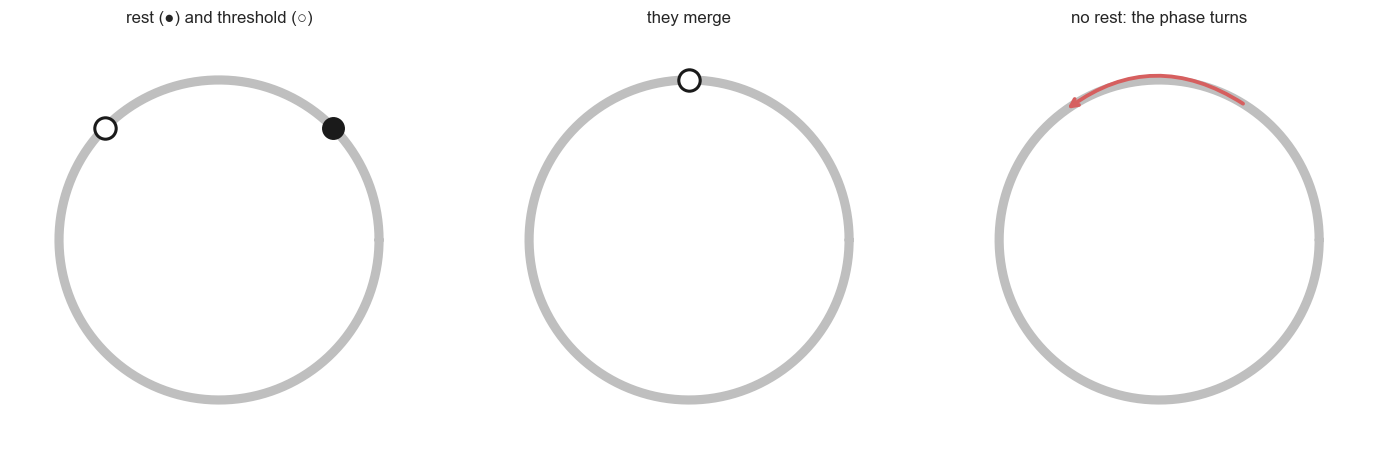

In [7]:
# @title SNIC on the active rotator: rest and threshold merge on the circle, then the phase turns (dphi/dt = omega - sin phi)
fig, ax = plt.subplots(1, 3, figsize=(13, 4.2))
c = np.linspace(0, 2 * np.pi, 300)
for a_, w in zip(ax, [0.7, 1.0, 1.1]):
    a_.plot(np.cos(c), np.sin(c), c="0.75", lw=6)
    if w <= 1:
        p1 = np.arcsin(w); p2 = np.pi - p1                          # rest (stable) and threshold (unstable)
        a_.plot(np.cos(p1), np.sin(p1), "o", ms=14, c="k"); a_.plot(np.cos(p2), np.sin(p2), "o", ms=14, mfc="w", mec="k", mew=2)
    else:
        a_.annotate("", xy=(np.cos(2.2), np.sin(2.2)), xytext=(np.cos(1.0), np.sin(1.0)),
                    arrowprops=dict(arrowstyle="->", color="C3", lw=2.5, connectionstyle="arc3,rad=0.35"))
    a_.set(aspect="equal", xticks=[], yticks=[], xlim=(-1.3, 1.3), ylim=(-1.3, 1.3),
           title={0.7: "rest (●) and threshold (○)", 1.0: "they merge", 1.1: "no rest: the phase turns"}[w])
    for s in a_.spines.values(): s.set_visible(False)
plt.tight_layout(); plt.show()

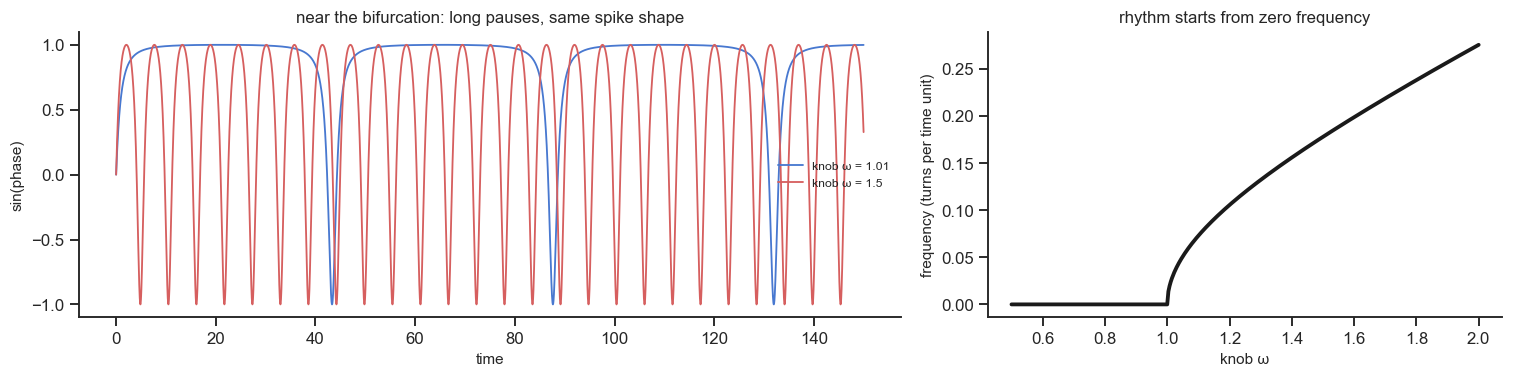

In [8]:
# @title SNIC: just past the bifurcation spikes are full-size but rare; the frequency grows from zero
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6), gridspec_kw=dict(width_ratios=[1.6, 1]))
for w, col in [(1.01, "C0"), (1.5, "C3")]:
    phi = neurons.active_rotator(omega=w, a=-1.0, T=150, dt=1e-3, phi0=0.0)
    ax[0].plot(np.arange(phi.size)[::20] * 1e-3, np.sin(phi[::20]), c=col, lw=1.2, label=f"knob ω = {w}")
ax[0].set(xlabel="time", ylabel="sin(phase)", title="near the bifurcation: long pauses, same spike shape"); ax[0].legend(fontsize=8)
w = np.linspace(0.5, 2, 400)
ax[1].plot(w, np.sqrt(np.clip(w**2 - 1, 0, None)) / (2 * np.pi), "k", lw=2.5)
ax[1].set(xlabel="knob ω", ylabel="frequency (turns per time unit)", title="rhythm starts from zero frequency")
plt.tight_layout(); plt.show()

Just past the bifurcation the phase lingers where rest used to be (its **ghost**), then makes a full turn: spikes of
**full size** but **very rare**. The frequency grows **from zero**: the "type I" neuron, opposite to Hodgkin–Huxley.
The QIF and θ neuron (NB02) go through the same SNIC, and the dripping tap of the slides is its everyday analogue.

<details><summary>Equation (for the curious)</summary>

$\dot\varphi = \omega - \sin\varphi$. For $\omega<1$ there are two fixed points ($\sin\varphi=\omega$); at $\omega=1$
they merge; above, the frequency is $\sqrt{\omega^2-1}/2\pi$.
</details>

## 5. Bistability, multistability, metastability

* **Bistability** (slides, NB05, NB11): two stable states for the same knob value. Its edges are two saddle-nodes,
  so switching on and off happens at different values (memory). The subcritical Hopf of section 2 is another kind:
  rest and a rhythm coexist.
* **Multistability**: many stable states at once. A network of bistable regions can hold many on/off patterns; in
  memory models (Hopfield) each stored memory is one of these states.
* **Metastability**: no state is truly stable, but the system **lingers** near some of them and then moves on, like
  the phase lingering near the ghost in section 4. With noise, a multistable system also hops between its states.
  Resting brain activity visiting and leaving a few connectivity patterns (dynamic FC, NB11) is often described this
  way.

## Take-home

| | size at onset | speed at onset | memory |
|---|---|---|---|
| supercritical Hopf | zero | fast | no |
| subcritical Hopf | large | fast | yes |
| SNIC | full | zero | no |

* Watching **how** a rhythm starts tells you which bifurcation you crossed, whatever the details of the model.
* Near a bifurcation a system is sensitive: noise produces large, slow fluctuations.
* **Next (Chapter 5):** one Stuart–Landau oscillator per brain region, coupled by the connectome (NB10).

### Homework
*At home, after the class.*
1. **Type I or type II?** Plot the frequency curve of the active rotator and the "current up" curve of Hodgkin–Huxley
   on the same (normalised) axes. Which one can fire at 1 spike/s?
2. **Switching off.** In section 2, change the delay of the second pulse after a spike (0 to 16 ms). For which delays
   does the neuron stop?
3. **Stuart–Landau.** Measure the size of the rhythm for $a = 0.05, 0.1, 0.2, 0.4$ and check the $\sqrt a$ law.

### References
* Strogatz SH (2015). *Nonlinear Dynamics and Chaos*, 2nd ed. Westview Press. (Ch. 3, 4 and 8.)
* Izhikevich EM (2007). *Dynamical Systems in Neuroscience*. MIT Press. (Ch. 6–7.)
* Rinzel J, Miller RN (1980). *Math Biosci* 49:27–59. Guttman R, Lewis S, Rinzel J (1980). *J Physiol* 305:377–395.
* Ermentrout GB, Kopell N (1986). Parabolic bursting in an excitable system coupled with a slow oscillation.
  *SIAM J Appl Math* 46:233–253.
* Hopfield JJ (1982). Neural networks and physical systems with emergent collective computational abilities.
  *PNAS* 79:2554–2558.
* Deco G, Jirsa VK (2012). Ongoing cortical activity at rest: criticality, multistability, and ghost attractors.
  *J Neurosci* 32:3366–3375.
* Tognoli E, Kelso JAS (2014). The metastable brain. *Neuron* 81:35–48.